# 02 · Ato 1: o negócio cresce?

**Projeto 1 · Tech Challenge – Fase 1 · POSTECH Data Analytics (FIAP)**
Matheus Benjamin Aquino Silva
*Trilha do projeto: o que fazer para as vendas da Olist crescerem cada vez mais?*

**Pergunta do investidor:** *vale a pena estar aqui?*

Este notebook continua o 01: parte das duas bases que ele salvou em `data/processed/` (`pedidos` e `itens`) e olha a receita da Olist por vários ângulos, um de cada vez: quanto cresceu, se o crescimento é de verdade ou só inflação, de onde ele veio, quando as pessoas compram, o que se vende, quem vende e onde estão os clientes.

**Perguntas que o notebook responde**

| Bloco | Perguntas | Seção |
|---|---|---|
| Tamanho e crescimento | P1. Quanto a Olist vendeu na janela? · P2. Quanto cresceu de um ano para o outro? · P3. O crescimento é real ou inflação? · P4. Em que momento o crescimento para? | 2, 3, 4 e 5 |
| De onde vem o crescimento | P5. Mais pedidos ou pedidos mais caros? · P6. O ticket médio mudou? · P7. Média ou mediana representa o pedido típico? | 6 e 7 |
| Quando se compra | P8. Em que dia e horário? · P9. Qual o tamanho da Black Friday? | 8 e 9 |
| O que se vende | P10. Quantas categorias fazem 80% da receita? · P11. As categorias líderes mudaram? | 10 |
| Quem vende | P12. A receita está concentrada em poucos vendedores? · P13. Há risco de dependência? | 11 |
| Onde se compra | P14. A receita acompanha a população das regiões? · P15. Qual estado compra mais por habitante? · P16. Onde está a oportunidade de expansão? | 12 |
| Fechamento | P17. A Olist cresce de forma sustentável? | 13 |

**Hipóteses testadas** (definidas em `docs/metodologia.md`):
- **H1**: o crescimento é consistente, não só um pico de Black Friday.
- **H8**: a receita depende de poucas categorias ou de poucos vendedores.

**Palavras que aparecem bastante**

| Termo | O que significa |
|---|---|
| **Vendas** | A receita bruta de vendas: preço dos produtos + frete, somados por pedido (decisão D3) |
| **Ticket médio** | Quanto, em média, cada pedido vale: receita ÷ número de pedidos |
| **IPCA** | O índice oficial de inflação do Brasil. Serve para corrigir valores antigos para preços de hoje |
| **Receita real** | A receita já corrigida pela inflação. É a forma justa de comparar meses diferentes |

**Como ler este notebook:** cada seção abre com o objetivo, executa o código e fecha com um bloco **Leitura**, que interpreta o resultado e responde à pergunta correspondente.

## 1. Bibliotecas e bases
O primeiro passo prepara o ambiente e carrega as bases do notebook 01:
- localiza a **raiz do projeto** (a pasta que contém `src/`) e importa os módulos `config`, `dados`, `externos` e `viz`;
- define a função `br()`, que escreve os números no padrão brasileiro (97.905 · 20,8);
- lê `pedidos.pkl` e `itens.pkl` de `data/processed/`. O formato PKL é usado porque preserva os tipos das colunas (datas, booleanos); o CSV, salvo junto, serve para conferência em outras ferramentas;
- confere se as bases chegaram íntegras: um pedido por linha e a mesma receita em `pedidos` e em `itens`.

In [1]:
# ============================================================
# IMPORTAÇÃO DAS BIBLIOTECAS
# ============================================================

import sys
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import matplotlib.dates as mdates
import seaborn as sns
from matplotlib.patches import Patch

# ============================================================
# LOCALIZAR RAIZ DO PROJETO
# ============================================================

RAIZ = Path.cwd().resolve()

while not (RAIZ / "src").is_dir():
    if RAIZ == RAIZ.parent:
        raise FileNotFoundError("Não foi possível localizar a pasta 'src'.")
    RAIZ = RAIZ.parent

if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

# ============================================================
# IMPORTAR MÓDULOS DO PROJETO
# ============================================================

from src import config, dados, externos, viz

# ============================================================
# FORMATAÇÃO BRASILEIRA
# ============================================================

def br(x, casas=0):
    """Número no padrão brasileiro: 97.905 · 20,8"""
    return (
        f"{x:,.{casas}f}"
        .replace(",", "X")
        .replace(".", ",")
        .replace("X", ".")
    )

def sinal(x):
    """'+' para valores positivos (o negativo já traz o '-')."""
    return "+" if x > 0 else ""

# ============================================================
# CONFIGURAÇÕES VISUAIS
# ============================================================

viz.aplicar_estilo()

# tabelas exibidas também no padrão brasileiro (2 casas decimais)
pd.set_option("display.float_format", lambda x: br(x, 2))
pd.set_option("display.max_columns", 50)

# ============================================================
# PASTA DAS BASES PROCESSADAS (SAÍDA DO NOTEBOOK 01)
# ============================================================

PASTA_PROCESSADOS = RAIZ / "data" / "processed"

if not PASTA_PROCESSADOS.is_dir():
    raise FileNotFoundError(f"Pasta não encontrada: {PASTA_PROCESSADOS}")

print(f"Raiz do projeto: {RAIZ}")
print(f"Bases lidas de:  {PASTA_PROCESSADOS.relative_to(RAIZ)}")

Raiz do projeto: /home/claude/projeto-1-tech-challenge
Bases lidas de:  data/processed


In [2]:
# ============================================================
# CONTINUIDADE DO NOTEBOOK 01: CARREGAR AS BASES
# ============================================================

arquivos = {nome: PASTA_PROCESSADOS / f"{nome}.pkl" for nome in ["pedidos", "itens"]}

for nome, caminho in arquivos.items():
    if not caminho.exists():
        raise FileNotFoundError(
            f"{caminho.relative_to(RAIZ)} não encontrado. Rode o notebook 01 primeiro."
        )

# PKL preserva os tipos originais, incluindo as colunas de data
pedidos = pd.read_pickle(arquivos["pedidos"])
itens = pd.read_pickle(arquivos["itens"])

print("=" * 60)
print("BASES CARREGADAS")
print("=" * 60)
for nome, df in {"pedidos": pedidos, "itens": itens}.items():
    gerado_em = datetime.fromtimestamp(arquivos[nome].stat().st_mtime)
    print(
        f"{nome:8} ← {arquivos[nome].name} · gerado em {gerado_em:%d/%m/%Y %H:%M} · "
        f"{br(df.shape[0])} linhas × {df.shape[1]} colunas"
    )

# ============================================================
# CONFERÊNCIA DA INTEGRIDADE DOS DADOS
# ============================================================

# Cada pedido aparece apenas uma vez
assert pedidos["order_id"].is_unique, "Erro: existem pedidos duplicados"

# A receita somada pelos pedidos é igual à receita somada pelos itens
receita_pedidos = pedidos["gmv"].sum()
receita_itens = (itens["preco"] + itens["frete"]).sum()
assert abs(receita_pedidos - receita_itens) < 0.01, (
    "Erro: receita de pedidos diferente da receita de itens"
)

print("\nConferência OK: 1 linha por pedido e receita de pedidos = receita de itens.")
print(f"Receita pedidos: R$ {br(receita_pedidos, 2)}")
print(f"Receita itens:   R$ {br(receita_itens, 2)}")

BASES CARREGADAS
pedidos  ← pedidos.pkl · gerado em 22/10/2026 21:22 · 99.441 linhas × 43 colunas
itens    ← itens.pkl · gerado em 22/10/2026 21:22 · 112.650 linhas × 21 colunas

Conferência OK: 1 linha por pedido e receita de pedidos = receita de itens.
Receita pedidos: R$ 15.843.553,24
Receita itens:   R$ 15.843.553,24


## 2. Recorte da análise
Para falar de receita, o recorte considera apenas:
- pedidos dentro da janela de jan/2017 a ago/2018 (`na_janela`, decisão D1);
- que viraram venda, ou seja, sem cancelados e indisponíveis (`gerou_venda`, decisão D2);
- com valor registrado (`gmv` preenchido).

Também é criada a **receita real**: a receita de cada mês corrigida pelo IPCA para preços de ago/2018. Sem essa correção, parte do crescimento seria apenas inflação. O IPCA vem do Banco Central (série SGS 433) e é o dado externo que complementa a base da Olist.

In [3]:
fator = externos.fator_ipca()

# fator por mês, com 4 casas para mostrar a diferença entre os meses
display(
    fator.rename(index=lambda d: d.strftime("%m/%Y"))
    .map(lambda v: br(v, 4))
    .to_frame("fator IPCA")
    .T
)

vendas = pedidos[pedidos["na_janela"] & pedidos["gerou_venda"] & pedidos["gmv"].notna()].copy()
vendas["gmv_real"] = vendas["gmv"] * vendas["mes"].map(fator)
print(f"Pedidos no recorte: {br(len(vendas))} de {br(len(pedidos))}")
display(vendas[["order_id", "mes", "uf_cliente", "qtd_itens", "valor_produtos", "valor_frete", "gmv", "gmv_real"]].head())

mes,01/2017,02/2017,03/2017,04/2017,05/2017,06/2017,07/2017,08/2017,09/2017,10/2017,11/2017,12/2017,01/2018,02/2018,03/2018,04/2018,05/2018,06/2018,07/2018,08/2018
fator IPCA,"1,0548","1,0513","1,0487","1,0472","1,0440","1,0464","1,0439","1,0419","1,0403","1,0359","1,0330","1,0285","1,0255","1,0222","1,0213","1,0191","1,0150","1,0024","0,9991","1,0000"


,order_id,mes,uf_cliente,qtd_itens,valor_produtos,valor_frete,gmv,gmv_real
329,ec7a019261fce44180373d45b442d78f,2017-01-01,PR,"1,00","10,90","8,72","19,62","20,70"
330,b95a0a8bd30aece4e94e81f0591249d8,2017-01-01,PR,"1,00","10,90","8,72","19,62","20,70"
331,38bcb524e1c38c2c1b60600a80fc8999,2017-01-01,PR,"1,00","2,90","8,72","11,62","12,26"
332,7a18a504c1a4b32d883e68de2e1a7db0,2017-01-01,PR,"1,00","7,90","8,72","16,62","17,53"
333,6acecf438369055d9243e121045cca74,2017-01-01,PR,"1,00","9,90","8,72","18,62","19,64"


Pedidos no recorte: 97.905 de 99.441


**Leitura:**

| Elemento | O que é | Valor |
|---|---|---|
| Mês-base | Mês cujos preços servem de referência (fator = 1,0000) | ago/2018, último mês completo da base |
| Fator de jan/2017 | Inflação acumulada de fev/2017 a ago/2018 | 1,0548 (R$ 100 da época ≈ R$ 105,48 em ago/2018) |
| Fator de jul/2018 | Único abaixo de 1, porque ago/2018 teve deflação (−0,09%) | 0,9991 |
| Recorte | Pedidos que entram em toda a análise de receita | 97.905 de 99.441 (o recorte retira cerca de 1,5%) |

**Como a correção funciona:** receita real = receita do mês × fator do mês. Quanto mais antigo o mês, mais inflação ele acumula até ago/2018 e maior é o fator. A inflação do período foi baixa, mas não é zero; a seção 4 mostra o efeito mês a mês.

## 3. Visão geral: mesmo período, um ano depois (P1 e P2)
A comparação justa é entre os **mesmos meses** de cada ano (jan–ago), porque 2018 só tem dados até agosto. Comparar o ano inteiro de 2017 com oito meses de 2018 distorceria o resultado.

In [4]:
def resumo(df):
    return pd.Series({
        "pedidos": len(df),
        "clientes": df["customer_unique_id"].nunique(),
        "receita nominal (R$ mi)": df["gmv"].sum() / 1e6,
        "receita real (R$ mi)": df["gmv_real"].sum() / 1e6,
        "ticket médio (R$)": df["gmv"].mean(),
        "itens por pedido": df["qtd_itens"].mean(),
        "frete / receita (%)": 100 * df["valor_frete"].sum() / df["gmv"].sum(),
    })

m = vendas["mes"]
comparacao = pd.DataFrame({
    "jan–ago/2017": resumo(vendas[(m >= "2017-01-01") & (m <= "2017-08-01")]),
    "jan–ago/2018": resumo(vendas[(m >= "2018-01-01") & (m <= "2018-08-01")]),
})
comparacao["variação %"] = 100 * (comparacao.iloc[:, 1] / comparacao.iloc[:, 0] - 1)
comparacao

,jan–ago/2017,jan–ago/2018,variação %
pedidos,"22.562,00","53.530,00","137,26"
clientes,"21.936,00","52.336,00","138,58"
receita nominal (R$ mi),"3,57","8,59","140,37"
receita real (R$ mi),"3,74","8,71","132,91"
ticket médio (R$),"158,45","160,53","1,31"
itens por pedido,"1,13","1,14","0,75"
frete / receita (%),"13,82","14,57","5,42"


**Leitura:**

**Objetivo da tabela.** A receita pode ser decomposta em **receita = número de pedidos × ticket médio**, e o ticket médio depende dos itens por pedido, do preço e do frete. A tabela compara cada uma dessas peças entre **jan–ago/2017** e **jan–ago/2018** para identificar **de onde veio o crescimento**. São usados os mesmos oito meses em cada ano porque a base de 2018 termina em agosto.

| Linha | O que mede | Pergunta que responde | Resultado | Interpretação |
|---|---|---|---|---|
| **Pedidos** | Quantidade de pedidos que viraram venda | A empresa vendeu mais vezes? | **+137%** | O volume mais que dobrou |
| **Clientes** | Pessoas distintas (`customer_unique_id`) | Entraram mais compradores? | **+139%** | Cresce junto com os pedidos, porque quase todo cliente compra uma única vez |
| **Receita nominal** | Soma das vendas em reais da época | Quanto a receita cresceu "no papel"? | **+140%** | Inclui o efeito da inflação |
| **Receita real** | Vendas corrigidas pelo IPCA (preços de ago/2018) | Quanto a receita cresceu de fato? | **+133%** | Crescimento verdadeiro; cerca de 7 p.p. do valor nominal eram inflação |
| **Ticket médio** | Receita ÷ número de pedidos | Cada pedido ficou mais caro? | **≈ estável** | O cliente gasta, por compra, o mesmo que em 2017 |
| **Itens por pedido** | Média de itens no carrinho | O cliente passou a levar mais produtos? | **≈ estável** | O carrinho não aumentou |
| **Frete / receita** | Participação do frete no valor pago | O frete passou a pesar mais? | **≈ estável** | O crescimento não veio de cobrar mais frete |

**Conclusão parcial.** A receita real cresceu 133%, enquanto o valor de cada pedido ficou estável. Portanto, o crescimento veio da **quantidade de clientes**, e não de cada cliente gastar mais.

**Implicação para o investidor.** Um crescimento sustentado apenas pela entrada de clientes novos depende de manter a aquisição acelerando, o que tem custo e limite. Quando a aquisição desacelera, a receita para junto. A seção 5 verifica se isso ocorreu, e o notebook 04 mostra o outro lado do problema: quase nenhum cliente volta a comprar.

## 4. Receita sem e com a correção do IPCA (P3)
A série mensal é montada uma única vez (`mensal`) e reaproveitada nas seções seguintes. O gráfico compara, mês a mês, a receita **sem correção** (em reais da época) e **com correção** (em reais de ago/2018).

,pedidos,clientes,gmv,gmv_real,ticket
mes,,,,,
2017-01-01,787,753,"136.943,46","144.447,80","174,01"
2017-02-01,1718,1693,"283.561,69","298.116,75","165,05"
2017-03-01,2617,2577,"425.617,96","446.348,81","162,64"


,pedidos,clientes,gmv,gmv_real,ticket
mes,,,,,
2018-06-01,6145,6106,"1.020.381,90","1.022.827,79","166,05"
2018-07-01,6233,6172,"1.039.783,58","1.038.847,77","166,82"
2018-08-01,6421,6380,"996.973,51","996.973,51","155,27"


Receita total sem correção: R$ 15,68 mi
Receita total com correção: R$ 16,08 mi (+2,5%)


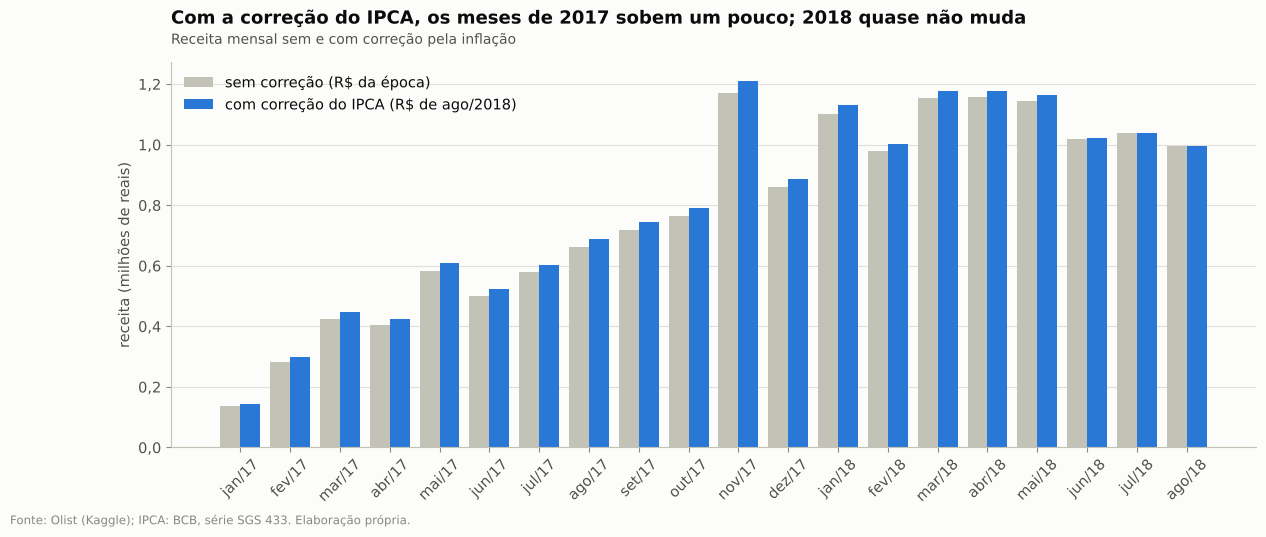

In [5]:
mensal = vendas.groupby("mes").agg(pedidos=("order_id", "count"),
                                   clientes=("customer_unique_id", "nunique"),
                                   gmv=("gmv", "sum"), gmv_real=("gmv_real", "sum"))
mensal["ticket"] = mensal["gmv"] / mensal["pedidos"]
display(mensal.head(3))
display(mensal.tail(3))

mensal_ipca = mensal[["gmv", "gmv_real"]].rename(columns={"gmv": "sem_ipca", "gmv_real": "com_ipca"}) / 1e6

fig, ax = plt.subplots(figsize=(14, 5))
x = np.arange(len(mensal_ipca))
ax.bar(x - 0.2, mensal_ipca["sem_ipca"], width=0.4, color=viz.CONTEXTO, label="sem correção (R$ da época)")
ax.bar(x + 0.2, mensal_ipca["com_ipca"], width=0.4, color=viz.DESTAQUE, label="com correção do IPCA (R$ de ago/2018)")

meses = ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"]
ax.set_xticks(x, [f"{meses[d.month - 1]}/{str(d.year)[2:]}" for d in mensal_ipca.index], rotation=45)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: br(v, 1)))
ax.set_ylabel("receita (milhões de reais)")
ax.legend(loc="upper left")
viz.titulo(ax, "Com a correção do IPCA, os meses de 2017 sobem um pouco; 2018 quase não muda",
           "Receita mensal sem e com correção pela inflação")
viz.fonte(fig, "Fonte: Olist (Kaggle); IPCA: BCB, série SGS 433. Elaboração própria.")
viz.salvar_figura(fig, "02_receita_com_sem_ipca")
plt.show()

# total do período, sem e com correção
total_sem, total_com = mensal_ipca["sem_ipca"].sum(), mensal_ipca["com_ipca"].sum()
print(f"Receita total sem correção: R$ {br(total_sem, 2)} mi")
print(f"Receita total com correção: R$ {br(total_com, 2)} mi ({sinal(total_com / total_sem - 1)}{br(100 * (total_com / total_sem - 1), 1)}%)")

**Leitura:**

| O que observar | Resultado | Interpretação |
|---|---|---|
| Barras de 2017 | A azul fica visivelmente acima da cinza | Meses antigos acumulam mais inflação até ago/2018, então a correção é maior |
| Barras de 2018 | As duas praticamente iguais | Meses próximos do mês-base quase não são corrigidos |
| Receita total do período | R$ 15,68 mi sem correção · R$ 16,08 mi com correção (+2,5%) | O efeito no total é pequeno |
| Crescimento jan–ago/2018 × jan–ago/2017 (tabela da seção 3) | +140% nominal · **+133% real** | Cerca de 7 pontos percentuais do crescimento aparente eram inflação |

**Resposta à P3:** o crescimento é real. A inflação de 2017–2018 foi baixa (2,95% em 2017) e não muda a conclusão, mas a partir daqui a análise usa sempre a **receita real**, que é a forma correta de comparar períodos diferentes.

## 5. A trajetória: cresceu e parou (P4)
Para medir o ritmo, usa-se o **crescimento médio mensal composto**: a taxa fixa que, aplicada todo mês, leva do primeiro ao último valor do período.

**Fórmula:** `(valor final ÷ valor inicial) ^ (1 ÷ número de intervalos) − 1`

Exemplo: se a receita vai de 100 para 200 em 4 meses, a taxa é de cerca de +19% ao mês, porque 100 × 1,19 × 1,19 × 1,19 × 1,19 ≈ 200.

Em 2017 o cálculo para em outubro, para que a Black Friday de novembro, um pico fora da curva, não infle a conta.

In [6]:
def crescimento_medio_mensal(serie):
    return (serie.iloc[-1] / serie.iloc[0]) ** (1 / (len(serie) - 1)) - 1

cresc_2017 = crescimento_medio_mensal(mensal.loc["2017-01":"2017-10", "gmv_real"])
cresc_2018 = crescimento_medio_mensal(mensal.loc["2018-01":"2018-08", "gmv_real"])
media_2018 = mensal.loc["2018", "gmv_real"].mean()

print(f"Crescimento médio mensal · jan–out/2017: {sinal(cresc_2017)}{br(100 * cresc_2017, 1)}% ao mês")
print(f"Crescimento médio mensal · jan–ago/2018: {sinal(cresc_2018)}{br(100 * cresc_2018, 1)}% ao mês")
print(f"Receita real média em 2018: R$ {br(media_2018 / 1e6, 2)} mi por mês")

Crescimento médio mensal · jan–out/2017: +20,8% ao mês
Crescimento médio mensal · jan–ago/2018: -1,8% ao mês
Receita real média em 2018: R$ 1,09 mi por mês


**Leitura:**

| Período | Crescimento médio mensal | O que significa |
|---|---|---|
| jan–out/2017 | **+20,8% ao mês** | Crescimento acelerado, todo mês |
| jan–ago/2018 | **−1,8% ao mês** | O crescimento parou e recuou levemente |
| Média de 2018 | **R$ 1,09 mi por mês** | Patamar em que a receita estacionou |

O gráfico abaixo mostra essa mudança de regime.

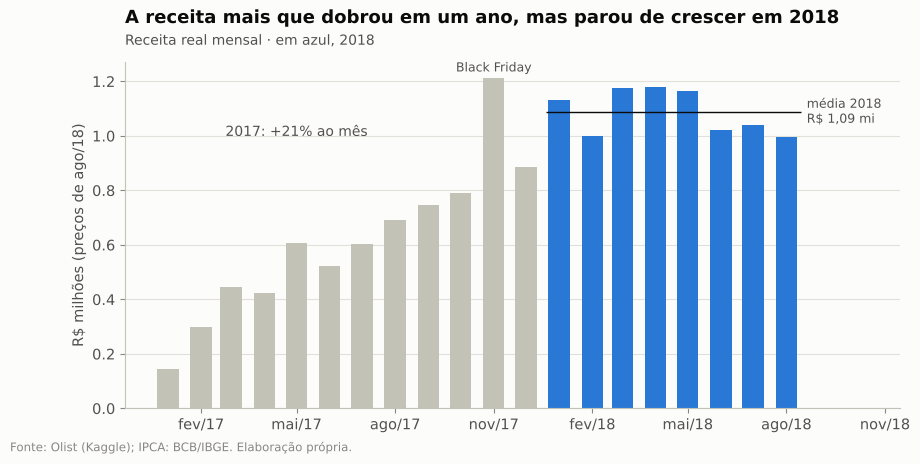

In [7]:
fig, ax = plt.subplots()
cores = [viz.DESTAQUE if d.year == 2018 else viz.CONTEXTO for d in mensal.index]
ax.bar(mensal.index, mensal["gmv_real"] / 1e6, width=20, color=cores)
ax.hlines(media_2018 / 1e6, pd.Timestamp("2017-12-20"), pd.Timestamp("2018-08-15"), color=viz.TINTA, lw=1)
ax.text(pd.Timestamp("2018-08-20"), media_2018 / 1e6, f"média 2018\nR$ {media_2018 / 1e6:.2f} mi".replace(".", ","),
        va="center", fontsize=9, color=viz.TINTA_SECUNDARIA)
ax.annotate("Black Friday", xy=(pd.Timestamp("2017-11-01"), mensal.loc["2017-11-01", "gmv_real"] / 1e6),
            xytext=(0, 5), textcoords="offset points", ha="center", fontsize=9, color=viz.TINTA_SECUNDARIA)
ax.text(pd.Timestamp("2017-05-01"), 1.0, f"2017: {100 * cresc_2017:+.0f}% ao mês", ha="center",
        fontsize=10, color=viz.TINTA_SECUNDARIA)
ax.set_xlim(right=pd.Timestamp("2018-11-15"))
ax.set_ylabel("R$ milhões (preços de ago/18)")
viz.eixo_mensal(ax)
viz.titulo(ax, "A receita mais que dobrou em um ano, mas parou de crescer em 2018",
           "Receita real mensal · em azul, 2018")
viz.fonte(fig, "Fonte: Olist (Kaggle); IPCA: BCB/IBGE. Elaboração própria.")
viz.salvar_figura(fig, "02_gmv_real_mensal")
plt.show()

**Leitura (P4): este é o gráfico mais importante do notebook.**

| Período | O que o gráfico mostra | Interpretação |
|---|---|---|
| **2017** | Subida contínua, cerca de +21% ao mês | Fase de crescimento acelerado |
| **2018** | Um platô em torno de **R$ 1,09 milhão por mês**, com leve queda (−1,8% ao mês) | O crescimento parou |

O +133% do ano é **herança de 2017**. Para o investidor, a pergunta deixa de ser "cresce?" e passa a ser "**por que parou?**". Os Atos 2 e 3 (notebooks 03 e 04) respondem.

**H1: parcialmente confirmada.** O crescimento foi real e não se resume à Black Friday, mas parou em 2018.

## 6. Pedidos, clientes e ticket: de onde veio o crescimento (P5 e P6)
A receita é o produto de **quantidade de pedidos × ticket médio**. Separando os dois fatores, fica claro qual deles puxou o crescimento.

Pedidos feitos por clientes de primeira compra: 96,7%
Menor % de pedidos de 1ª compra em um mês: 95,6%


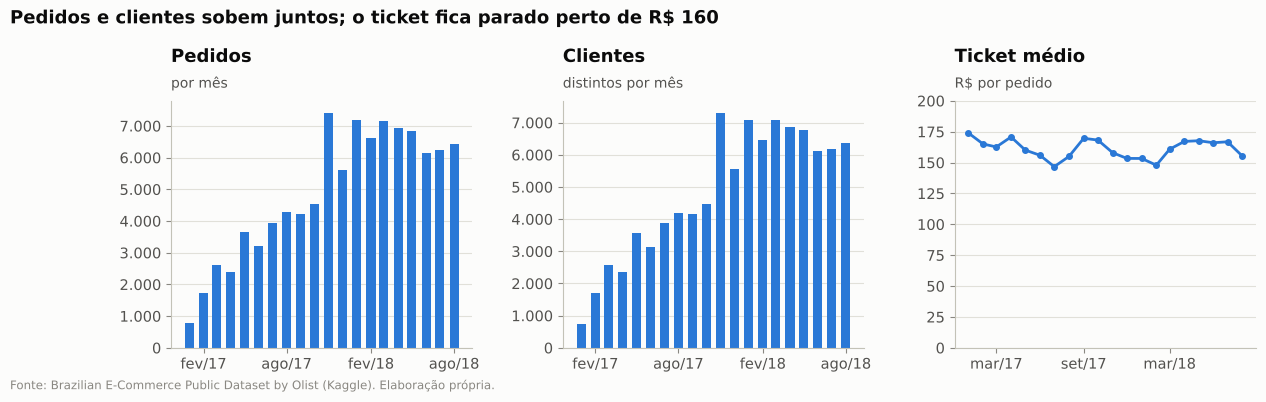

In [8]:
fig, axs = plt.subplots(1, 3, figsize=(14, 3.8))
axs[0].bar(mensal.index, mensal["pedidos"], width=20, color=viz.DESTAQUE)
axs[0].yaxis.set_major_formatter(mtick.FuncFormatter(viz.formato_milhar))
viz.titulo(axs[0], "Pedidos", "por mês")
axs[1].bar(mensal.index, mensal["clientes"], width=20, color=viz.DESTAQUE)
axs[1].yaxis.set_major_formatter(mtick.FuncFormatter(viz.formato_milhar))
viz.titulo(axs[1], "Clientes", "distintos por mês")
axs[2].plot(mensal.index, mensal["ticket"], color=viz.DESTAQUE, marker="o", ms=4)
axs[2].set_ylim(0, 200)
viz.titulo(axs[2], "Ticket médio", "R$ por pedido")
for a in axs:
    viz.eixo_mensal(a, 6)
fig.suptitle("Pedidos e clientes sobem juntos; o ticket fica parado perto de R$ 160",
             x=0.01, ha="left", fontsize=13, fontweight="bold", y=1.0)
fig.subplots_adjust(top=0.76, wspace=0.3)
viz.fonte(fig)
viz.salvar_figura(fig, "02_pedidos_e_ticket")
plt.show()

novos = vendas.groupby("mes")["ordem_compra_cliente"].apply(lambda s: (s == 1).mean() * 100)
print(f"Pedidos feitos por clientes de primeira compra: {br(100 * (vendas['ordem_compra_cliente'] == 1).mean(), 1)}%")
print(f"Menor % de pedidos de 1ª compra em um mês: {br(novos.min(), 1)}%")

**Leitura (P5 e P6): os três gráficos contam a mesma história.**

| Gráfico | O que aparece | Interpretação |
|---|---|---|
| Pedidos e clientes | Exatamente o mesmo desenho | Cada pedido novo é, quase sempre, um cliente novo |
| Ticket médio | Oscila entre R$ 147 e R$ 174, sem tendência | Cada pedido vale o mesmo que antes |
| Tipo de compra | **97% dos pedidos são de clientes comprando pela primeira vez**, todo mês | Quase não existe cliente voltando |

**Conclusão:** o motor do crescimento foi a **aquisição de clientes novos**. Quando a aquisição parou de acelerar em 2018, a receita parou junto.

## 7. Quanto custa um pedido típico (P7)
A média de R$ 160 resume a base em um número, mas esconde a forma da distribuição. O gráfico de densidade (KDE), dividido em quartis, mostra como os valores se espalham e onde fica cada quarto dos pedidos.

Q1: R$ 61,96 · mediana: R$ 105,28 · Q3: R$ 176,69 · P90: R$ 306,96 · média: R$ 160,19


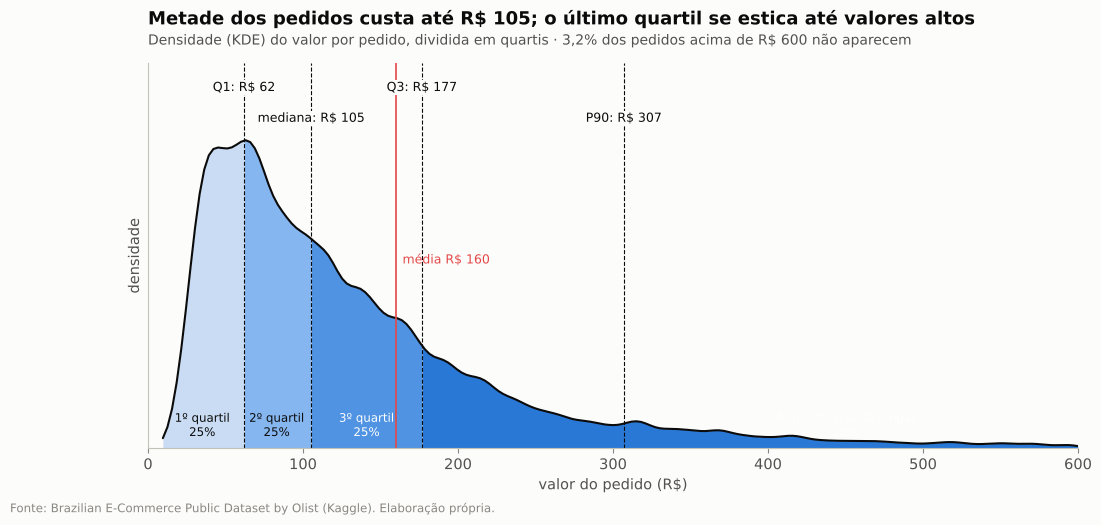

In [9]:
valores = vendas["gmv"]
q1, q2, q3, p90 = valores.quantile([.25, .5, .75, .9])
corte = 600  # eixo até R$ 600 (cobre ~97% dos pedidos)
fora = (valores > corte).mean()

fig, ax = plt.subplots(figsize=(12, 5))
sns.kdeplot(
    x=valores[valores <= corte], ax=ax,
    color=viz.TINTA, lw=1.5, bw_adjust=0.6, cut=0,
)

# pinto a área de cada faixa de quartil com um tom de azul
linha = ax.lines[0]
x0, y0 = linha.get_xdata(), linha.get_ydata()
x = np.linspace(x0.min(), x0.max(), 3000)  # grade fina: sem frestas
y = np.interp(x, x0, y0)

faixas = [
    (x.min(), q1, "#c9dcf3", "1º quartil"),
    (q1, q2, "#86b6ef", "2º quartil"),
    (q2, q3, "#4f93e2", "3º quartil"),
    (q3, corte, viz.DESTAQUE, "4º quartil (cauda longa)"),
]
for ini, fim, cor, rotulo in faixas:
    ax.fill_between(x, y, where=(x >= ini) & (x <= fim), color=cor, lw=0)

# rótulo de cada quartil dentro da faixa, na base da curva
posicoes_x = [35, 83, 141, 450]
for (ini, fim, cor, rotulo), xt in zip(faixas, posicoes_x):
    cor_texto = "white" if cor in ("#4f93e2", viz.DESTAQUE) else viz.TINTA
    ax.text(
        xt, y.max() * 0.04, rotulo + "\n25%",
        ha="center", fontsize=8.5, color=cor_texto,
    )

# linhas dos cortes com o valor no topo
cortes = [
    (q1, "Q1", 1.16),
    (q2, "mediana", 1.06),
    (q3, "Q3", 1.16),
    (p90, "P90", 1.06),
]
for v, nome, alt in cortes:
    ax.axvline(v, color=viz.TINTA, lw=0.8, ls="--")
    ax.text(
        v, y.max() * alt, f"{nome}: R\\$ {br(v)}",
        ha="center", fontsize=9,
        bbox=dict(fc=viz.SUPERFICIE, ec="none", pad=1),
    )

# média em vermelho
media = valores.mean()
ax.axvline(media, color=viz.ALERTA, lw=1.2)
ax.text(
    media + 4, y.max() * 0.6, f"média R\\$ {br(media)}",
    color=viz.ALERTA, fontsize=9,
)

ax.set_ylim(0, y.max() * 1.25)
ax.set_xlim(0, corte)
ax.set_xlabel("valor do pedido (R$)")
ax.set_ylabel("densidade")
ax.set_yticks([])

titulo = (
    f"Metade dos pedidos custa até R$ {br(q2)}; "
    "o último quartil se estica até valores altos"
)
subtitulo = (
    "Densidade (KDE) do valor por pedido, dividida em quartis · "
    f"{br(100 * fora, 1)}% dos pedidos acima de R$ {corte} não aparecem"
)
viz.titulo(ax, titulo, subtitulo)
viz.fonte(fig)
viz.salvar_figura(fig, "02_kde_ticket_quartis")
plt.show()

print(
    f"Q1: R$ {br(q1, 2)} · "
    f"mediana: R$ {br(q2, 2)} · "
    f"Q3: R$ {br(q3, 2)} · "
    f"P90: R$ {br(p90, 2)} · "
    f"média: R$ {br(media, 2)}"
)

**Leitura:** o KDE (estimativa de densidade) mostra a forma da distribuição como uma curva suave: quanto mais alta a curva, mais pedidos existem naquele valor. A área sob a curva foi dividida nos quatro quartis, e cada faixa colorida concentra 25% dos pedidos.

| Faixa | Intervalo | O que representa |
|---|---|---|
| 1º quartil | até R$ 62 | Pedidos de baixo valor; aqui está o pico da curva, o valor mais comum |
| 2º quartil | R$ 62 a R$ 105 | Até a mediana: metade dos pedidos custa até R$ 105 |
| 3º quartil | R$ 105 a R$ 177 | Pedidos médios |
| 4º quartil | acima de R$ 177 | A cauda longa: faixa larga, com poucos pedidos espalhados até valores altos |

- As três primeiras faixas são estreitas porque concentram muitos pedidos em poucos reais. A quarta é larga porque seus pedidos estão espalhados.
- A **média (R$ 160)** fica à direita da **mediana (R$ 105)**, puxada pela cauda longa. Por isso a mediana representa melhor o pedido típico.
- 90% dos pedidos custam até R$ 307 (P90).

**Conclusão:** a Olist é um marketplace de compras pequenas e frequentes no perfil. É justamente o tipo de compra em que se esperaria recompra, o que torna a baixa retenção (notebook 04) ainda mais relevante.

## 8. Quando as pessoas compram (P8)
A distribuição dos pedidos por dia da semana e por hora indica a rotina do cliente.

Pedidos entre 10h e 22h: 81,6% · madrugada (0h–6h): 5,3%


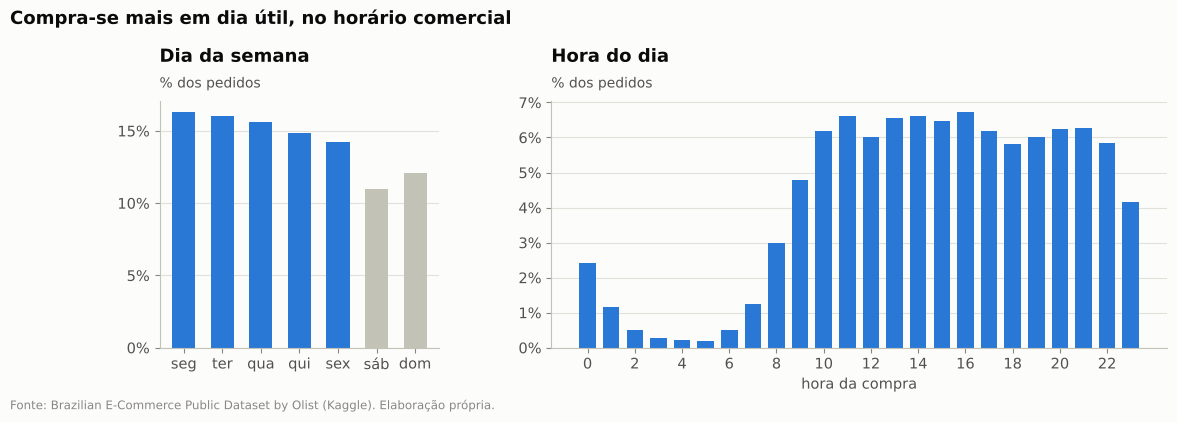

In [10]:
dias = ["seg", "ter", "qua", "qui", "sex", "sáb", "dom"]
por_dia = vendas.groupby(vendas["order_purchase_timestamp"].dt.dayofweek).size() / len(vendas) * 100
por_hora = vendas.groupby(vendas["order_purchase_timestamp"].dt.hour).size() / len(vendas) * 100

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1, 2.2]})
a1.bar(dias, por_dia.values, color=[viz.CONTEXTO if d >= 5 else viz.DESTAQUE for d in por_dia.index], width=0.6)
a1.yaxis.set_major_locator(mtick.MultipleLocator(5))
a1.yaxis.set_major_formatter(viz.formato_pct())
viz.titulo(a1, "Dia da semana", "% dos pedidos")
a2.bar(por_hora.index, por_hora.values, color=viz.DESTAQUE, width=0.7)
a2.set_xticks(range(0, 24, 2))
a2.yaxis.set_major_formatter(viz.formato_pct())
a2.set_xlabel("hora da compra")
viz.titulo(a2, "Hora do dia", "% dos pedidos")
fig.suptitle("Compra-se mais em dia útil, no horário comercial", x=0.01, ha="left",
             fontsize=13, fontweight="bold", y=1.0)
fig.subplots_adjust(top=0.76, wspace=0.25)
viz.fonte(fig)
viz.salvar_figura(fig, "02_dia_hora")
plt.show()
print(f"Pedidos entre 10h e 22h: {br(por_hora.loc[10:22].sum(), 1)}% · madrugada (0h–6h): {br(por_hora.loc[0:6].sum(), 1)}%")

**Leitura (P8):**

| Medida | Resultado | Interpretação |
|---|---|---|
| Dias mais fortes | Segunda e terça, cerca de 16% dos pedidos cada | O começo da semana concentra as compras |
| Dias mais fracos | Sábado e domingo, 11–12% | O fim de semana vende menos |
| Horário | 82% dos pedidos saem entre 10h e 22h; a madrugada quase não vende | Padrão de quem compra **no intervalo do trabalho ou à noite** |

**Para o negócio:** esse padrão orienta o horário das campanhas e o reforço do atendimento.

## 9. O tamanho da Black Friday (P9)
A Black Friday de 24/11/2017 é comparada com a média diária de outubro, um mês sem datas promocionais.

Pedidos em 24/11/2017: 1.166 · média diária de outubro: 147 · 7,9x


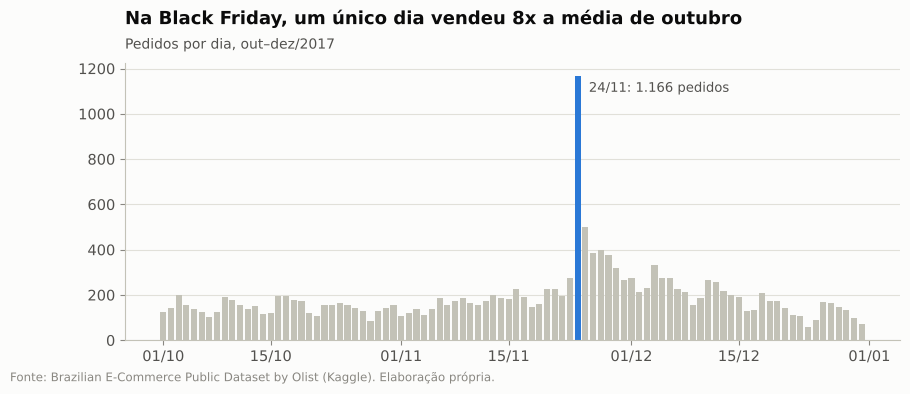

In [11]:
diario = vendas.groupby(vendas["order_purchase_timestamp"].dt.normalize()).size()
bf = pd.Timestamp("2017-11-24")
media_out = diario.loc["2017-10"].mean()
print(f"Pedidos em 24/11/2017: {br(diario.loc[bf])} · média diária de outubro: {br(media_out)} · {br(diario.loc[bf] / media_out, 1)}x")

fig, ax = plt.subplots(figsize=(10, 3.6))
trecho = diario.loc["2017-10-01":"2017-12-31"]
ax.bar(trecho.index, trecho.values, width=0.8, color=[viz.DESTAQUE if d == bf else viz.CONTEXTO for d in trecho.index])
ax.annotate(f"24/11: {diario.loc[bf]:,} pedidos".replace(",", "."), xy=(bf, diario.loc[bf]),
            xytext=(8, -4), textcoords="offset points", fontsize=9.5, color=viz.TINTA_SECUNDARIA, va="top")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m"))
viz.titulo(ax, f"Na Black Friday, um único dia vendeu {diario.loc[bf] / media_out:.0f}x a média de outubro",
           "Pedidos por dia, out–dez/2017")
viz.fonte(fig)
viz.salvar_figura(fig, "02_black_friday")
plt.show()

**Leitura (P9):** um único dia de Black Friday vendeu quase o equivalente a **8 dias normais**, e a semana seguinte ainda ficou acima do normal.

É receita, mas também um **teste de estresse da logística**: muita entrega de uma vez. No Ato 2 (notebook 03) aparece o custo disso: o atraso das entregas sobe para 12% em novembro.

## 10. O que se vende: categorias (P10 e P11 · H8)
A análise de categorias usa a base de **itens**, porque um pedido pode ter produtos de categorias diferentes. A receita de cada item é preço + frete, a mesma definição da base de pedidos.

Categorias: 74 · as 10 maiores somam 62,4% · são precisas 18 para chegar a 80%


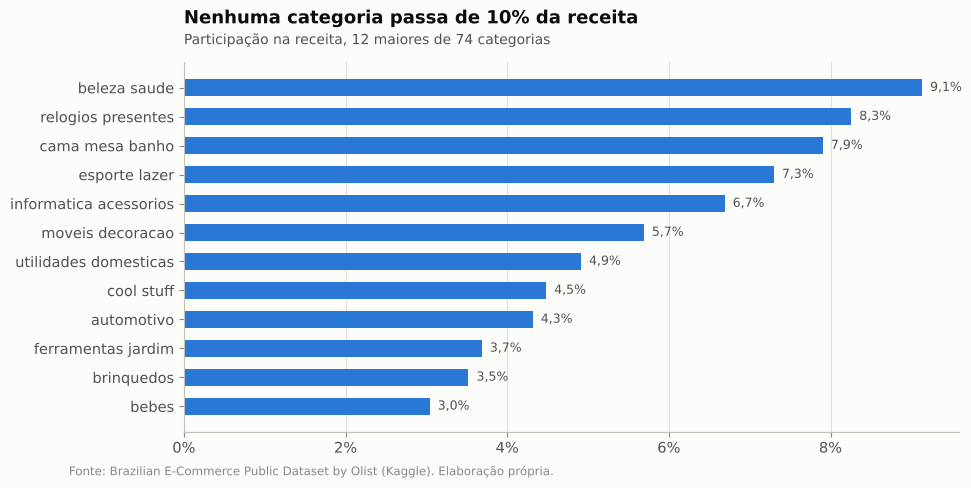

In [12]:
itens_venda = itens[itens["order_id"].isin(vendas["order_id"])].assign(gmv=lambda d: d["preco"] + d["frete"])
por_categoria = itens_venda.groupby("categoria")["gmv"].sum().sort_values(ascending=False)
acum_cat = por_categoria.cumsum() / por_categoria.sum()
print(f"Categorias: {len(por_categoria)} · as 10 maiores somam {br(100 * acum_cat.iloc[9], 1)}% · "
      f"são precisas {(acum_cat < 0.8).sum() + 1} para chegar a 80%")

top = (por_categoria.head(12) / por_categoria.sum() * 100).sort_values()
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.barh(top.index, top.values, height=0.6, color=viz.DESTAQUE)
for y, v in enumerate(top.values):
    ax.text(v + 0.1, y, f"{v:.1f}%".replace(".", ","), va="center", fontsize=9, color=viz.TINTA_SECUNDARIA)
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
ax.xaxis.set_major_formatter(viz.formato_pct())
viz.titulo(ax, "Nenhuma categoria passa de 10% da receita",
           f"Participação na receita, 12 maiores de {len(por_categoria)} categorias")
viz.fonte(fig)
viz.salvar_figura(fig, "02_categorias")
plt.show()

**Leitura (P10):** o gráfico de Pareto ordena as categorias da que mais vende para a que menos vende e soma a receita acumulada. Ele responde à pergunta "poucas categorias fazem quase tudo?".

| Medida | Resultado | Interpretação |
|---|---|---|
| Maior categoria | Beleza e saúde, com 9,1% da receita | Nenhuma categoria domina |
| Categorias para chegar a 80% da receita | **18** | A receita é bem distribuída: não há dependência de um único segmento |

Essa foto, porém, é do período inteiro. O próximo passo verifica se alguma categoria está ganhando espaço ao longo do tempo.

categoria,beleza saude,relogios presentes,cama mesa banho,esporte lazer,informatica acessorios
trimestre,,,,,
2017-01-01,"8,30","5,50","6,50","7,30","5,90"
2017-04-01,"7,80","6,40","7,40","7,30","7,70"
2017-07-01,"7,90","6,60","10,40","7,80","6,10"
2017-10-01,"7,40","9,00","7,90","7,20","6,20"
2018-01-01,"8,80","7,90","7,60","9,00","9,70"
2018-04-01,"10,20","9,90","7,80","6,10","5,40"
2018-07-01,"12,70","9,10","7,10","6,20","4,80"


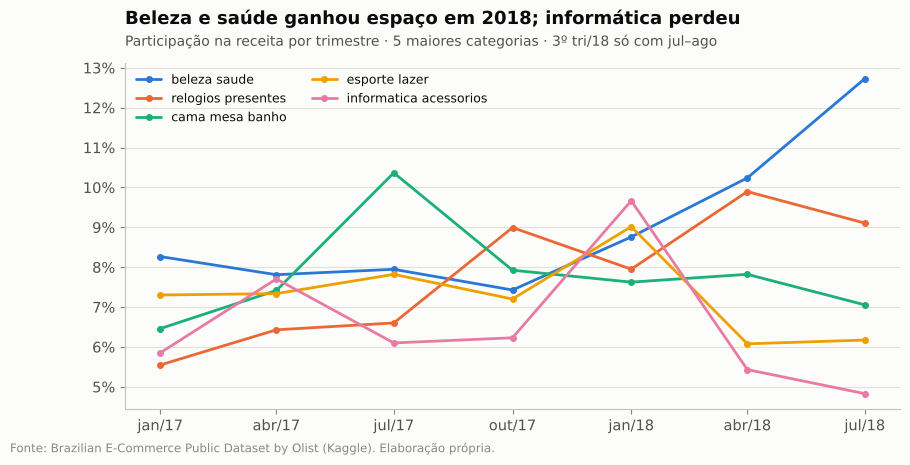

In [13]:
itens_venda["trimestre"] = itens_venda["order_purchase_timestamp"].dt.to_period("Q").dt.to_timestamp()
top5 = por_categoria.head(5).index
tri = itens_venda.pivot_table(index="trimestre", columns="categoria", values="gmv", aggfunc="sum")
part = tri[top5].div(tri.sum(axis=1), axis=0) * 100
display(part.round(1))

fig, ax = plt.subplots()
for i, c in enumerate(top5):
    ax.plot(part.index, part[c], marker="o", ms=4, color=viz.CATEGORICA[i], label=c)
ax.yaxis.set_major_formatter(viz.formato_pct())
ax.legend(loc="upper left", ncol=2, fontsize=9)
viz.eixo_mensal(ax)
viz.titulo(ax, "Beleza e saúde ganhou espaço em 2018; informática perdeu",
           "Participação na receita por trimestre · 5 maiores categorias · 3º tri/18 só com jul–ago")
viz.fonte(fig)
viz.salvar_figura(fig, "02_categorias_tempo")
plt.show()

**Leitura (P11):**

| Categoria | O que aconteceu | Interpretação |
|---|---|---|
| Beleza e saúde | Subiu de cerca de 8% para 10–13% em 2018 | Ganhou espaço |
| Informática e acessórios | Pico no 1º tri/18 (9,7%) e depois caiu para menos de 5% | Movimento pontual |
| As demais | Oscilam sem tendência clara | Estáveis |

**Conclusão:** o mix muda um pouco, mas nenhuma categoria passa a dominar. **H8 não se confirma para categorias.**

## 11. Quem vende: vendedores (P12 e P13 · H8)
A análise ordena os vendedores do que mais faturou para o que menos faturou e mede quanto da receita cada grupo concentra. Primeiro vêm um resumo numérico e os 10 maiores vendedores; depois, o histograma da receita por vendedor, com as cores indicando a posição de cada um no ranking. Os nomes não aparecem: a base só traz o `seller_id` anonimizado.

In [14]:
vend = itens_venda.groupby("seller_id").agg(receita=("gmv", "sum"), pedidos=("order_id", "nunique"),
                                            uf=("uf_vendedor", "first")).sort_values("receita", ascending=False)
vend["% acumulado"] = 100 * vend["receita"].cumsum() / vend["receita"].sum()
n = len(vend)
print(f"Vendedores: {br(n)}")
print(f"1% maiores ({int(n * .01)}): {br(vend['% acumulado'].iloc[int(n * .01) - 1], 1)}% da receita")
print(f"10% maiores ({int(n * .10)}): {br(vend['% acumulado'].iloc[int(n * .10) - 1], 1)}% da receita")
print(f"Vendedores com menos de 10 pedidos no período: {br(100 * (vend['pedidos'] < 10).mean(), 1)}%")

top10 = vend.head(10).copy()
top10.index = [f"vendedor {i}" for i in range(1, 11)]
display(top10.assign(receita=lambda d: d["receita"].round(0)))

,receita,pedidos,uf,% acumulado
vendedor 1,"249.393,00",1131,SP,"1,59"
vendedor 2,"239.536,00",982,SP,"3,12"
vendedor 3,"235.857,00",358,BA,"4,62"
vendedor 4,"235.359,00",1804,SP,"6,12"
vendedor 5,"202.862,00",584,SP,"7,42"
vendedor 6,"185.192,00",1314,SP,"8,60"
vendedor 7,"177.415,00",331,SP,"9,73"
vendedor 8,"172.861,00",915,SP,"10,83"
vendedor 9,"162.607,00",1159,SP,"11,87"
vendedor 10,"160.583,00",1286,SP,"12,89"


Vendedores: 3.029
1% maiores (30): 25,3% da receita
10% maiores (302): 66,5% da receita
Vendedores com menos de 10 pedidos no período: 58,5%


,vendedores,receita,% da receita,receita média (R$)
grupo,,,,
90% restantes,2727,"5.258.906,70","33,50","1.928,50"
10% maiores (sem o 1%),272,"6.450.416,90","41,10","23.714,80"
1% maiores,30,"3.974.383,10","25,30","132.479,40"


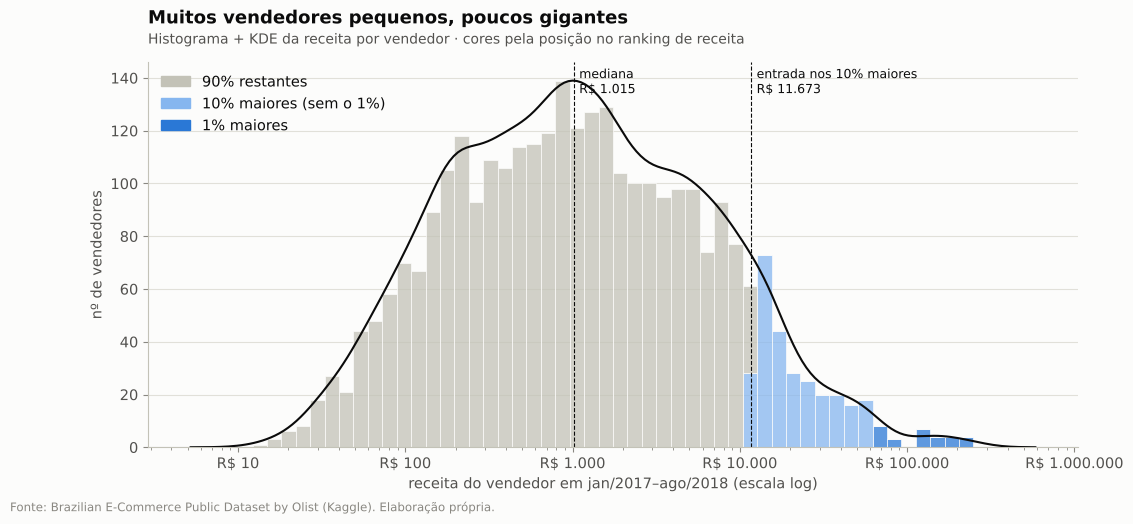

In [15]:
# grupos de vendedores pela posição no ranking de receita
n = len(vend)
posicao = np.arange(1, n + 1) / n  # vend já está ordenado do maior para o menor
grupo = np.select(
    [posicao <= 0.01, posicao <= 0.10],
    ["1% maiores", "10% maiores (sem o 1%)"],
    default="90% restantes",
)
base_vend = vend.assign(grupo=grupo)

cores_grupo = {
    "90% restantes": viz.CONTEXTO,
    "10% maiores (sem o 1%)": "#86b6ef",
    "1% maiores": viz.DESTAQUE,
}

fig, ax = plt.subplots(figsize=(12, 5))
sns.histplot(
    data=base_vend, x="receita", hue="grupo", hue_order=list(cores_grupo),
    palette=cores_grupo, log_scale=True, bins=50, multiple="stack",
    edgecolor=viz.SUPERFICIE, linewidth=0.5, ax=ax, legend=False,
)
# curva KDE por cima (eixo próprio, escondido: serve só para desenhar a forma)
sns.kdeplot(
    data=base_vend, x="receita", log_scale=True, ax=ax.twinx(),
    color=viz.TINTA, lw=1.5, bw_adjust=0.8,
).set_axis_off()

# linhas de referência
mediana_v = base_vend["receita"].median()
corte_10 = base_vend.loc[base_vend["grupo"] != "90% restantes", "receita"].min()
referencias = [
    (mediana_v, "mediana"),
    (corte_10, "entrada nos 10% maiores"),
]
for v, nome in referencias:
    ax.axvline(v, color=viz.TINTA, lw=0.8, ls="--")
    ax.text(
        v * 1.08, ax.get_ylim()[1] * 0.92,
        f"{nome}\nR\\$ {br(v)}", fontsize=9,
    )

ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"R$ {br(v)}"))
ax.set_xlabel("receita do vendedor em jan/2017–ago/2018 (escala log)")
ax.set_ylabel("nº de vendedores")
ax.legend(
    handles=[Patch(color=c, label=g) for g, c in cores_grupo.items()],
    loc="upper left",
)

titulo = "Muitos vendedores pequenos, poucos gigantes"
subtitulo = (
    "Histograma + KDE da receita por vendedor · "
    "cores pela posição no ranking de receita"
)
viz.titulo(ax, titulo, subtitulo)
viz.fonte(fig)
viz.salvar_figura(fig, "02_hist_vendedores")
plt.show()

# tabela de apoio: quanto cada grupo representa
resumo_grupos = base_vend.groupby("grupo").agg(
    vendedores=("receita", "size"),
    receita=("receita", "sum"),
)
total = resumo_grupos["receita"].sum()
resumo_grupos["% da receita"] = 100 * resumo_grupos["receita"] / total
resumo_grupos["receita média (R$)"] = (
    resumo_grupos["receita"] / resumo_grupos["vendedores"]
)
display(resumo_grupos.loc[list(cores_grupo)].round(1))

**Leitura:** o histograma conta quantos vendedores existem em cada faixa de receita; a curva preta (KDE) mostra a forma suavizada dessa distribuição. O eixo horizontal está em escala logarítmica (cada marca vale 10 vezes a anterior), porque a receita dos vendedores vai de poucos reais a centenas de milhares.

**Como os grupos foram formados.** A receita considerada é o **total faturado por cada vendedor nos 20 meses da janela** (jan/2017 a ago/2018), e não um valor mensal. Os **3.029 vendedores** foram ordenados em fila, do que mais faturou para o que menos faturou, e a fila foi cortada **pela posição**:
- **1% maiores**: os 30 primeiros da fila (1% de 3.029);
- **10% maiores**: os 302 primeiros (o 1% está incluído neles);
- **90% restantes**: do 303º até o último.

Ou seja, os percentuais dos grupos se referem à **quantidade de vendedores**, não à receita. Os valores de corte (como os R$ 11.700) não foram definidos previamente: são consequência da fila, ou seja, o faturamento do vendedor que ficou exatamente na posição do corte.

| Grupo | Posição na fila | Vendedores | Faturamento de cada vendedor nos 20 meses | % da receita total |
|---|---|---|---|---|
| **1% maiores** (azul escuro) | 1º ao 30º | 30 | média de **R$ 132 mil** | **25,3%** |
| **10% maiores, sem o 1%** (azul claro) | 31º ao 302º | 272 | média de **R$ 24 mil**; o menor deles faturou cerca de **R$ 11.700** | **41,1%** |
| **90% restantes** (cinza) | 303º em diante | 2.727 | média de **R$ 1.900**; todos abaixo de cerca de R$ 11.700 | **33,5%** |

**Como ler a última coluna:** juntos, os 30 maiores vendedores somam 25,3% de toda a receita da Olist; somando os 302 maiores (1% + 10%), chega-se a **66%**. Os 2.727 vendedores restantes, 90% da base, respondem por apenas um terço do faturamento.

**Outros pontos de referência:**
- O vendedor do meio da fila (mediana) faturou cerca de **R$ 1.015** nos 20 meses: metade dos vendedores não passou desse valor.
- Um vendedor do 1% maior fatura, em média, **quase 70 vezes** mais que um vendedor dos 90% restantes.
- Como muitos vendedores entraram na plataforma durante o período, dividir o total por 20 não dá o faturamento mensal real de cada um.

**Conclusão:** **1 em cada 100 vendedores traz 1 em cada 4 reais da Olist.** O gráfico mostra, vendedor a vendedor, a concentração que os números acima resumem: a base é formada por muitos vendedores pequenos, e um grupo reduzido sustenta a maior parte da receita. Isso confirma a **H8 para vendedores** e indica um risco de dependência: a saída de poucos vendedores grandes teria impacto relevante no faturamento.

## 12. Onde estão os clientes (P14, P15 e P16)
Comparar estados pelo volume bruto favorece quem tem mais habitantes: volume não é desempenho. Por isso a métrica é **pedidos por 100 mil habitantes**, com a população do IBGE de 2018 (segundo dado externo do projeto).

,% da população,% da receita,pedidos por 100 mil hab.,ticket médio (R$)
regiao_cliente,,,,
Sudeste,"42,10","64,60","76,60","150,80"
Sul,"14,30","14,50","46,90","162,80"
Nordeste,"27,20","11,90","16,30","201,20"
Centro-Oeste,"7,70","6,40","35,50","177,00"
Norte,"8,70","2,60","10,10","223,30"


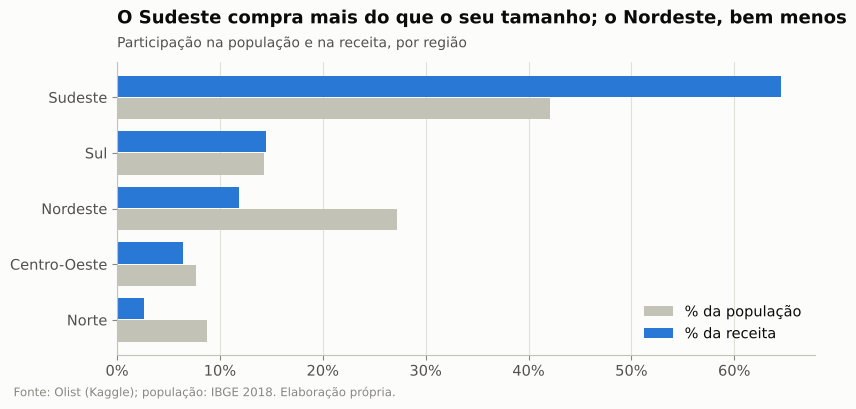

In [16]:
pop = externos.populacao_uf()
regiao = vendas.groupby("regiao_cliente").agg(pedidos=("order_id", "count"), gmv=("gmv", "sum"))
regiao = regiao.join(pop.groupby("regiao")["populacao_2018"].sum())
regiao["% da população"] = 100 * regiao["populacao_2018"] / regiao["populacao_2018"].sum()
regiao["% da receita"] = 100 * regiao["gmv"] / regiao["gmv"].sum()
regiao["pedidos por 100 mil hab."] = regiao["pedidos"] / regiao["populacao_2018"] * 1e5
regiao["ticket médio (R$)"] = regiao["gmv"] / regiao["pedidos"]
regiao = regiao.sort_values("% da receita", ascending=False)
display(regiao[["% da população", "% da receita", "pedidos por 100 mil hab.", "ticket médio (R$)"]].round(1))

fig, ax = plt.subplots(figsize=(9, 3.8))
y = np.arange(len(regiao))
ax.barh(y + 0.2, regiao["% da população"], height=0.38, color=viz.CONTEXTO, label="% da população")
ax.barh(y - 0.2, regiao["% da receita"], height=0.38, color=viz.DESTAQUE, label="% da receita")
ax.set_yticks(y, regiao.index); ax.invert_yaxis()
ax.xaxis.set_major_formatter(viz.formato_pct())
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
ax.legend(loc="lower right")
viz.titulo(ax, "O Sudeste compra mais do que o seu tamanho; o Nordeste, bem menos",
           "Participação na população e na receita, por região")
viz.fonte(fig, "Fonte: Olist (Kaggle); população: IBGE 2018. Elaboração própria.")
viz.salvar_figura(fig, "02_regiao_pop_receita")
plt.show()

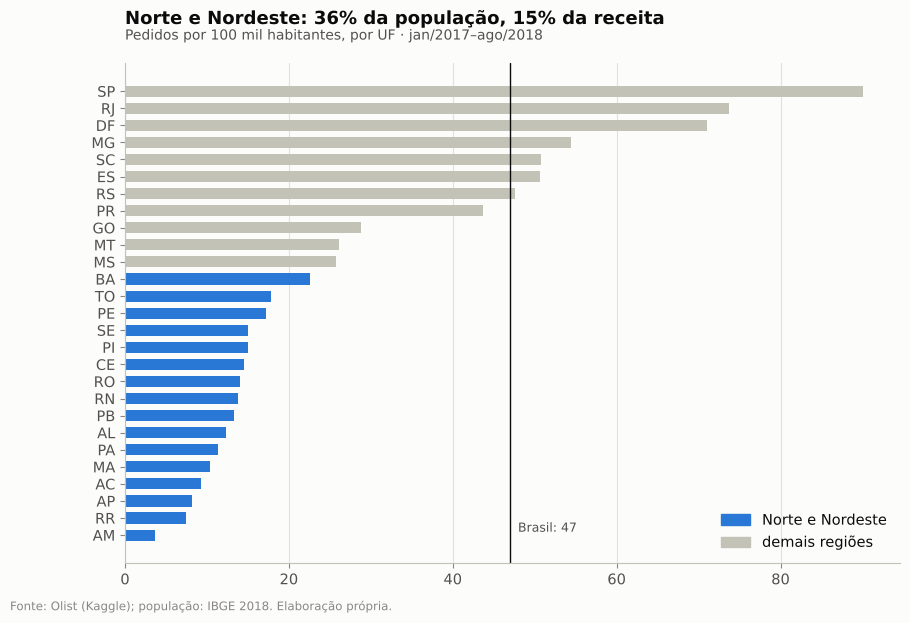

In [17]:
uf = vendas.groupby("uf_cliente").agg(pedidos=("order_id", "count")).join(pop)
uf["pedidos_por_100mil"] = uf["pedidos"] / uf["populacao_2018"] * 1e5
ordem = uf["pedidos_por_100mil"].sort_values()
media_br = uf["pedidos"].sum() / uf["populacao_2018"].sum() * 1e5

fig, ax = plt.subplots(figsize=(10, 6.5))
cores = [viz.DESTAQUE if pop.loc[u, "regiao"] in ("Norte", "Nordeste") else viz.CONTEXTO for u in ordem.index]
ax.barh(ordem.index, ordem.values, height=0.65, color=cores)
ax.axvline(media_br, color=viz.TINTA, lw=1)
ax.text(media_br + 1, 0.2, f"Brasil: {media_br:.0f}", fontsize=9, color=viz.TINTA_SECUNDARIA)
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
ax.legend(handles=[Patch(color=viz.DESTAQUE, label="Norte e Nordeste"), Patch(color=viz.CONTEXTO, label="demais regiões")],
          loc="lower right")
viz.titulo(ax, "Norte e Nordeste: 36% da população, 15% da receita",
           "Pedidos por 100 mil habitantes, por UF · jan/2017–ago/2018")
viz.fonte(fig, "Fonte: Olist (Kaggle); população: IBGE 2018. Elaboração própria.")
viz.salvar_figura(fig, "02_penetracao_uf")
plt.show()

In [18]:
tri_reg = vendas.assign(trimestre=vendas["mes"].dt.to_period("Q").dt.to_timestamp()) \
               .pivot_table(index="trimestre", columns="regiao_cliente", values="gmv", aggfunc="sum")
part_reg = tri_reg.div(tri_reg.sum(axis=1), axis=0) * 100
display(part_reg.round(1))

regiao_cliente,Centro-Oeste,Nordeste,Norte,Sudeste,Sul
trimestre,,,,,
2017-01-01,"7,30","10,80","4,30","61,40","16,20"
2017-04-01,"6,20","12,50","3,00","63,60","14,70"
2017-07-01,"6,40","13,60","2,90","62,60","14,60"
2017-10-01,"6,70","12,00","2,40","65,00","14,00"
2018-01-01,"6,20","11,70","2,50","64,90","14,60"
2018-04-01,"6,40","11,00","2,10","65,80","14,70"
2018-07-01,"6,40","11,90","2,50","65,60","13,60"


**Leitura (P14 e P15):** comparar estados pelo volume bruto favoreceria quem tem mais gente. Por isso a medida é a **penetração**: pedidos por 100 mil habitantes, que funciona como "quantos pedidos a Olist recebe a cada 100 mil moradores".

| Região | % da população | % da receita | Pedidos por 100 mil hab. | Ticket médio |
|---|---|---|---|---|
| **Sudeste** | 42,1% | **64,6%** | **76,6** | R$ 151 |
| Sul | 14,3% | 14,5% | 46,9 | R$ 163 |
| Centro-Oeste | 7,7% | 6,4% | 35,5 | R$ 177 |
| **Nordeste** | **27,2%** | 11,9% | **16,3** | R$ 201 |
| **Norte** | 8,7% | 2,6% | **10,1** | R$ 223 |

- **Norte e Nordeste** somam 36% da população e só 15% da receita. O Nordeste compra quase **5 vezes menos** por habitante que o Sudeste; o Norte, mais de 7 vezes menos.
- A participação de cada região **ficou estável** ao longo dos trimestres: a expansão não mudou o mapa.
- O ticket no Norte e no Nordeste é maior, em parte por causa do frete.

**Conclusão:** é o **maior espaço de crescimento** que os dados mostram. A tabela abaixo transforma isso numa lista de estados prioritários (P16).

In [19]:
# P16: estados grandes com penetração abaixo da média do Brasil = oportunidade de expansão
uf["% da população"] = 100 * uf["populacao_2018"] / uf["populacao_2018"].sum()
uf["pedidos se tivesse a média BR"] = uf["populacao_2018"] / 1e5 * media_br
uf["pedidos a ganhar"] = (uf["pedidos se tivesse a média BR"] - uf["pedidos"]).clip(lower=0)
oportunidade = (uf[uf["pedidos_por_100mil"] < media_br]
                .sort_values("pedidos a ganhar", ascending=False)
                [["regiao", "% da população", "pedidos_por_100mil", "pedidos", "pedidos a ganhar"]]
                .head(8).round(1))
display(oportunidade)
top3 = oportunidade.head(3)
print(f"Os 3 estados com mais pedidos a ganhar ({', '.join(top3.index)}) somam "
      f"{br(top3['pedidos a ganhar'].sum())} pedidos no período, "
      f"{br(100 * top3['pedidos a ganhar'].sum() / uf['pedidos'].sum())}% do total atual.")

,regiao,% da população,pedidos_por_100mil,pedidos,pedidos a ganhar
uf_cliente,,,,,
BA,Nordeste,"7,10","22,50",3340,"3.615,70"
PA,Norte,"4,10","11,30",965,"3.032,80"
CE,Nordeste,"4,40","14,50",1316,"2.945,70"
PE,Nordeste,"4,60","17,20",1636,"2.823,30"
MA,Nordeste,"3,40","10,40",732,"2.571,50"
AM,Norte,"2,00","3,60",147,"1.769,20"
PB,Nordeste,"1,90","13,30",530,"1.346,70"
GO,Centro-Oeste,"3,30","28,80",1990,"1.260,00"


Os 3 estados com mais pedidos a ganhar (BA, PA, CE) somam 9.594 pedidos no período, 10% do total atual.


**Leitura (P16):** a coluna **"pedidos a ganhar"** estima quantos pedidos a mais cada estado teria se comprasse na **média do Brasil** por habitante. A conta é: (penetração média do Brasil − penetração do estado) × população do estado ÷ 100 mil.

| Medida | Resultado | Interpretação |
|---|---|---|
| Estados no topo da lista | BA, PA e CE, todos no Norte e Nordeste | É onde a distância para a média é maior |
| Tamanho da oportunidade | Os 3 primeiros somam 9.594 pedidos a mais no período, **10% do total atual** | Só três estados já mexeriam na receita |

É uma medida do **tamanho da oportunidade**, não uma previsão: chegar à média depende de prazo e frete competitivos, que são o tema do notebook 03.

## 13. Conclusão do Ato 1 (P17)

| Pergunta | Resposta |
|---|---|
| O negócio cresce? | **Cresceu muito (+133% real no ano), mas parou em 2018**, num patamar de cerca de R$ 1,1 mi por mês |
| De onde veio o crescimento? | **Clientes novos.** 97% dos pedidos são de primeira compra; o ticket ficou parado em cerca de R$ 160 |
| Como é a compra típica? | Pequena (mediana de R$ 105), em dia útil e no horário comercial |
| Há risco de concentração? | **Baixo em categorias** (maior = 9%), **alto em vendedores** (10% fazem 66%, a maioria em SP) |
| Onde crescer? | **Norte e Nordeste**, com penetração 5 a 8 vezes menor que a do Sudeste |

| Hipótese | Resultado |
|---|---|
| H1: crescimento consistente além da Black Friday | ⚠️ Parcial: forte em 2017, parado em 2018 |
| H8: receita concentrada | ✅ Vendedores · ❌ Categorias |

**Resposta à P17:** o crescimento de 2017 foi real, mas não se sustentou em 2018 porque dependia de trazer clientes novos o tempo todo. As duas alavancas para retomá-lo aparecem nos próximos notebooks: **expandir fora do Sudeste** (o que exige logística) e **fazer o cliente voltar**.

**Próximo:** `03_logistica_satisfacao.ipynb`. O crescimento dependia de trazer clientes novos, e quase nenhum volta. O notebook 03 investiga a experiência de entrega: se a primeira compra atrasa ou chega incompleta, o cliente não volta e não recomenda. A logística também ajuda a explicar por que Norte e Nordeste, a maior oportunidade de expansão, compram tão pouco.